# Using Diffusion on prediction of video and motion

## Import the lib and initialize the parameters

In [1]:
import argparse
import os.path

import torch
from torch import nn,optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/2024-10-31_xacti_5fps')
# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])

cuda


## 1. Load the Dataset

In [3]:
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=False, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

100%|██████████| 65/65 [00:00<00:00, 170.76it/s]


metadata exists in: dataset/2024-10-31_xacti_5fps/test/metadata_40.pkl


## 2. Load the networks

In [4]:
from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])

## 3. Train the model

### 3.1 Continue from the checkpoint

In [5]:
from TimeSformer.VDT_cat_vm import VDT_cat

nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 100
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)

modelData = 'checkpoints_vae_seg/vae_40.pth.tar'
checkpoint = torch.load(modelData)
vae.load_state_dict(checkpoint['model_state_dict'])
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False



## 4. Tests

### 4.1 DDIM for generation

In [6]:
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

metadata exists in: dataset/data_20240807_processed/train/metadata_16.pkl


load model: success
li:0.215 ang:0.000
li:0.136 ang:0.100
li:0.304 ang:0.400
li:0.222 ang:0.400
li:0.132 ang:0.500
li:0.205 ang:0.400
li:0.258 ang:0.200
li:0.150 ang:0.000
li:0.194 ang:0.000
li:0.208 ang:-0.027
li:0.065 ang:0.037
li:0.078 ang:0.012
li:0.264 ang:0.009
li:0.116 ang:0.213
li:0.284 ang:0.292
li:0.259 ang:0.325
li:0.206 ang:-0.012
li:0.130 ang:0.039
li:0.228 ang:0.048
li:0.231 ang:0.016
li:0.213 ang:0.057
li:0.162 ang:0.107
li:0.146 ang:0.195
li:0.139 ang:0.098
li:0.197 ang:-0.001
li:0.164 ang:0.002
li:0.219 ang:-0.114
li:0.212 ang:-0.041
li:0.245 ang:-0.159
li:0.058 ang:0.035
li:0.123 ang:0.104
li:0.049 ang:-0.001
li:0.114 ang:-0.060
li:0.173 ang:0.046
li:0.167 ang:0.026
li:0.212 ang:0.078
li:0.154 ang:0.219
li:0.131 ang:0.104
li:0.297 ang:0.305
li:0.136 ang:0.057
li:0.155 ang:0.016
li:0.140 ang:-0.010
li:0.140 ang:0.026
li:0.163 ang:0.105
li:0.200 ang:0.051
li:0.226 ang:0.047
li:0.226 ang:0.238
li:0.241 ang:0.284
estimate time: 0.7966339588165283


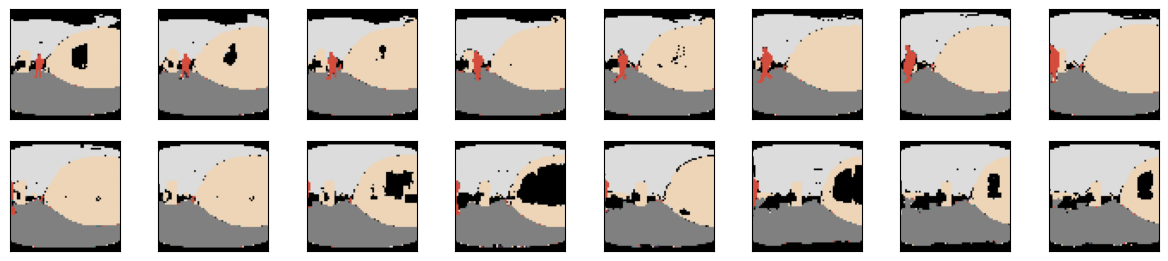

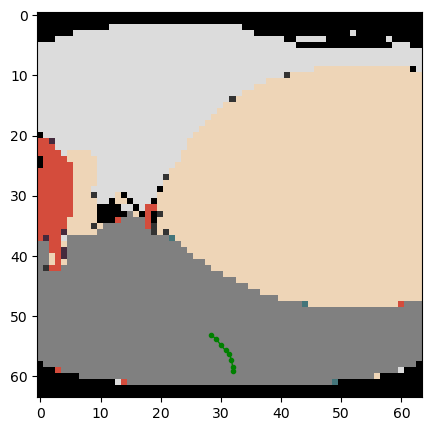

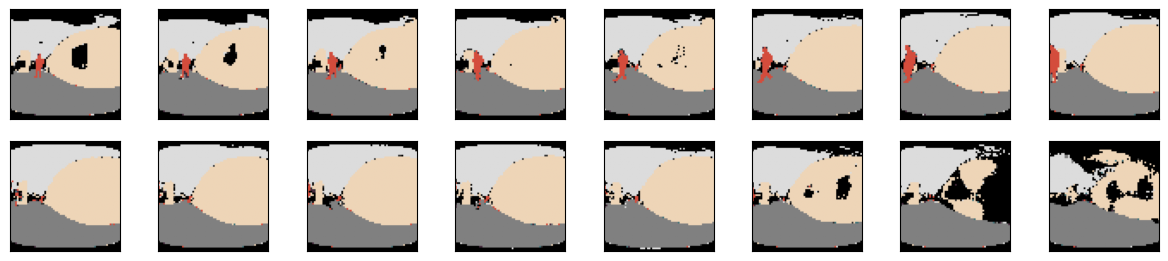

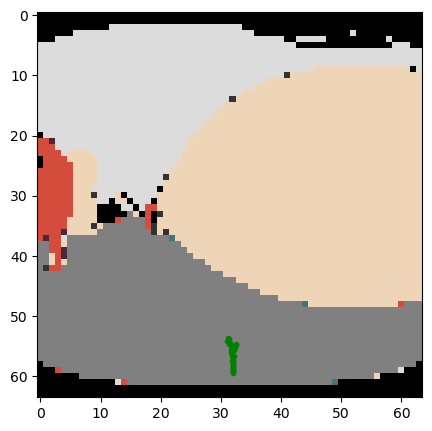

In [16]:
from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color
import time

modelData = '/home/xu/xu/robo_nav/checkpoints_mmVDT_cat_vae_seg/VDT_20240807_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels,depth=depth, hidden_size=hidden_size, model_path=modelData, _cuda=0, cat=True)

idx=1722 
# memo: data20240807 1720, 210, 510, 500, 3500

vis_id = 0 # the index for visualization, default = 0
pred_num = 5 # The number of multiple predictions

test = True
batch,_,_ = valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.reshape(1,2,16).permute(0,2,1).to(DEVICE)

vid = batch.permute(0,3,1,2).to(DEVICE)
enc_vid = vae.encode(vid).latent_dist.sample()
enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

a = enc_vid.to(DEVICE)
b = mot.to(DEVICE)
rec_mot_list = []

start_time = time.time()
################ Original image #############################
batch = batch.permute(0,3,1,2)
batch_rgb = gray2color(batch)
batch_rgb = torch.clamp(batch_rgb, 0,1)
visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,16,2), rgb=True)

# visual_img(batch.permute(0,2,3,1).reshape(1,16,64,64,9), b[vis_id].reshape(1,16,2))
for i in range(pred_num):
    if test:
        diff_a = torch.randn([1,16,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([1,16,2]).to(DEVICE)
    else:
        t = torch.tensor([args.iteration_num -1])
        diff_a, eps_vid = fw_diffusion_vid(a, alpha_cum, t)
        diff_b, eps_mot = fw_diffusion_mot(b, alpha_cum, t)
    
    # 0:prediction 1:backward 2:interpolation
    mask_vid, mask_motion = mask_generator(a,b,0)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)


    with torch.no_grad():
        
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
        rec_mot_list.append(rec_mot)
    
    rec_vid = rec_vid.reshape(16,input_size,input_size,in_channels-2).permute(0,3,1,2)
    dec_vid = vae.decode(rec_vid).sample

est_time = time.time() - start_time

################ Decoded image #############################
dec_rgb = gray2color(dec_vid)
dec_rgb = torch.clamp(dec_rgb, 0,1)
visual_vid_mmot(dec_rgb.permute(0,2,3,1), rec_mot_list, rgb=True)

print("estimate time:", est_time)



### Multi-result generation (Input with multiple batches)

In [6]:
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl


load model: success
428 dataset/2024-10-31_xacti_5fps/train/data_2024-10-23-17_44_24_7m_in_461_sec/25.mp4
li:0.287 ang:0.000
li:0.287 ang:-0.100
li:0.287 ang:0.000
li:0.315 ang:0.200
li:0.301 ang:0.200
li:0.266 ang:0.100
li:0.238 ang:0.000
li:0.259 ang:0.000
li:0.280 ang:0.100
li:0.280 ang:0.100
li:0.301 ang:0.100
li:0.273 ang:0.100
li:0.287 ang:0.300
li:0.315 ang:0.100
li:0.273 ang:0.100
li:0.238 ang:0.100
li:0.259 ang:0.000
li:0.287 ang:0.000
li:0.259 ang:0.000
li:0.287 ang:0.000
li:0.287 ang:0.000
li:0.294 ang:-0.100
li:0.266 ang:0.000
li:0.259 ang:0.000
li:0.259 ang:-0.100
li:0.315 ang:0.000
li:0.294 ang:-0.100
li:0.266 ang:-0.100
li:0.308 ang:-0.100
li:0.245 ang:0.000
li:0.265 ang:0.033
li:0.267 ang:0.001
li:0.253 ang:-0.005
li:0.231 ang:0.110
li:0.226 ang:0.076
li:0.250 ang:0.039
li:0.253 ang:-0.052
li:0.278 ang:0.010
li:0.262 ang:-0.000
li:0.253 ang:-0.006
li:0.251 ang:-0.069
li:0.235 ang:-0.107
li:0.232 ang:-0.108
li:0.252 ang:-0.023
li:0.240 ang:-0.029
li:0.257 ang:-0.026
li:0

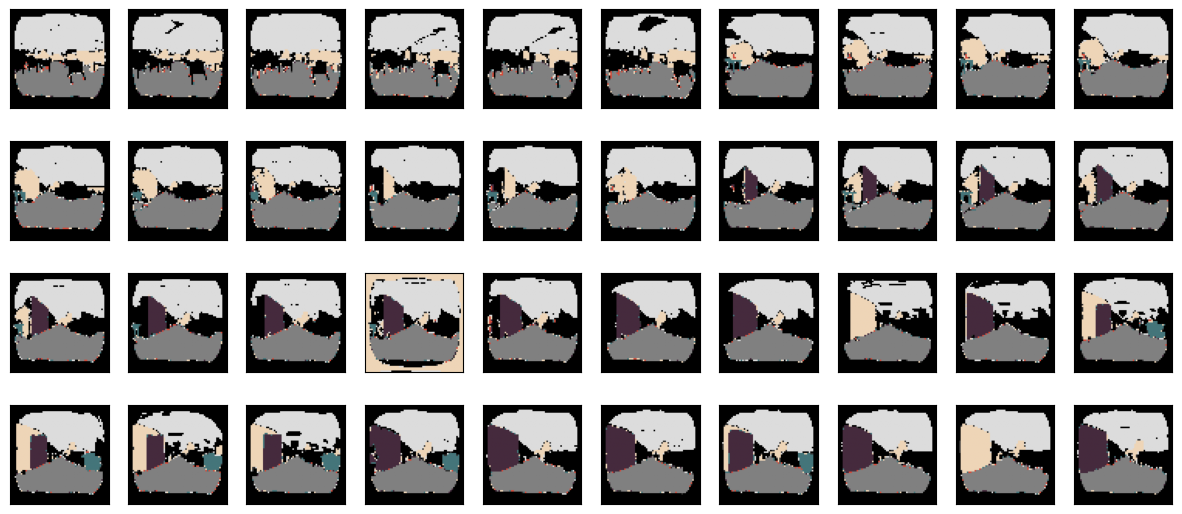

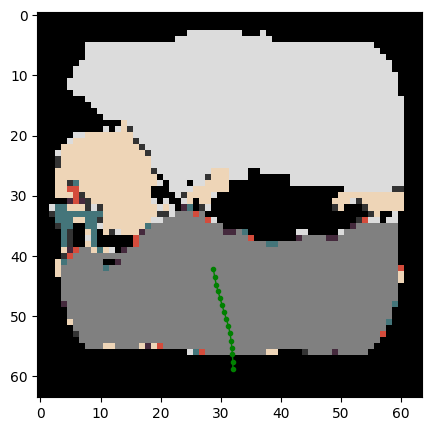

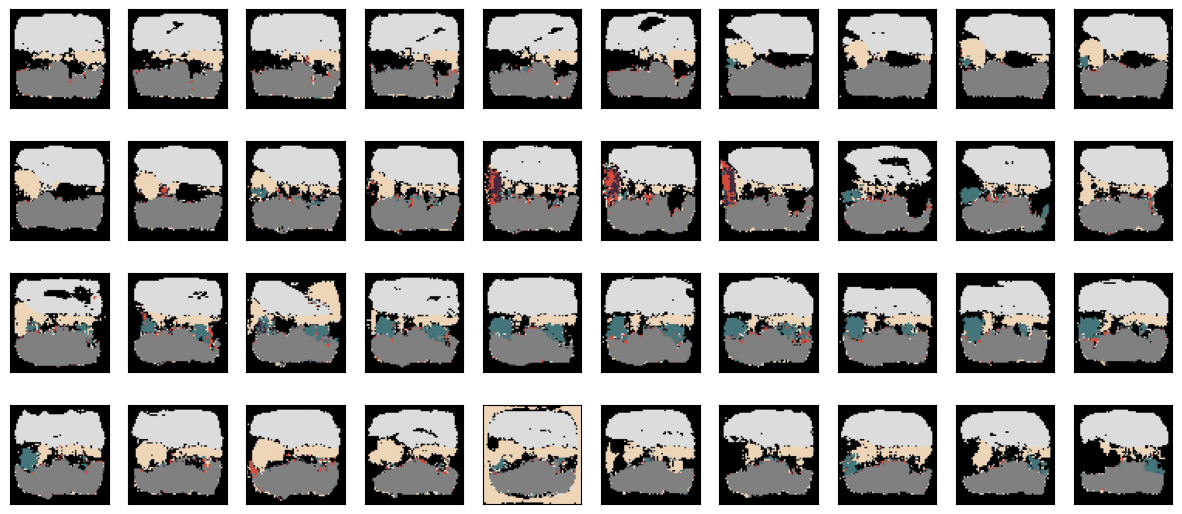

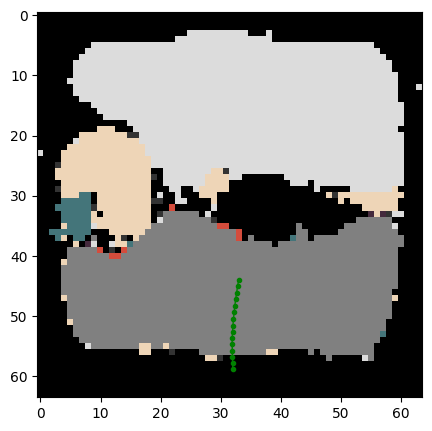

In [37]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color
import time

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20240807_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241006_mul_fps_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

idx=7000
# Pick a sample in the dataset
# memo: data20240807 100, 1715, 1720, 230, 250, 300, 520, 500, 3500, 6510, 6800, 10800, 11000, 12000, 15500

r = 3
vis_id = 0 # the index for visualization, default = 0
pred_num = 1 # The number of multiple predictions
frame_t = 10

test = True
batch, vid_idx, path = valid_dataset[idx]
print(vid_idx, path)
batch, mot = dict.values(batch)
mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

vid = batch.permute(0,3,1,2).to(DEVICE)
enc_vid = vae.encode(vid).latent_dist.sample()
enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

a = enc_vid.to(DEVICE)
b = mot.to(DEVICE)
rec_vid_list = []
rec_mot_list = []

################ Original image #############################
batch = batch.permute(0,3,1,2)
batch_rgb = gray2color(batch)
batch_rgb = torch.clamp(batch_rgb, 0,1)
visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

if test:
    diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
    diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

# Choose a mask type from 0 to 2
# 0: prediction 1: backward 2: interpolation, t means the current frame
mask_vid, mask_motion = mask_generator(diff_a,diff_b, idx=0, t=frame_t)
# print(mask_vid[0,4])
a = a.repeat(pred_num,1,1,1,1)
b = b.repeat(pred_num,1,1)
diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

start_time = time.time()

with torch.no_grad():
    rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
    
rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)
est_time = time.time() - start_time

################ Decode image #############################
for i in range(pred_num):  
    rec_mot_list.append(rec_mot[i])    
    dec_vid = vae.decode(rec_vid[i]).sample
    dec_rgb = gray2color(dec_vid)
    dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
    rec_vid_list.append(dec_rgb)

################ Select image (Naive selection) #############################
for t in range(pred_num):
    end_x,end_y = visual_vid_mmot(rec_vid_list[t], [rec_mot_list[t]], rgb=True, is_road=True, grid=False, frame_t=frame_t)
    end_x = int(end_x.numpy())
    end_y = int(end_y.numpy())
    # print(end_x, end_y)
    xx, yy = torch.meshgrid(torch.arange(args.resolution), torch.arange(args.resolution), indexing="ij")
    detect_mask = ((xx-end_y)**2 +(yy-end_x)**2) <= r **2
    detected_area = rec_vid_list[t][7][detect_mask]
    # Check the end point is on the floor
    result = torch.all(detected_area == 128/255)
    print(result)

print("estimate time:", est_time)



## 5. Visualization

### Load the dataset

In [7]:
data_origin_path = 'dataset/2024-10-31_xacti_5fps_origin'
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(data_origin_path, args.sequence_length,rgb=True, train=True, resolution=args.resolution)

# dataloader for the trainning
o_dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

# dataloader for the evaluation
o_dataset = Dataset(data_origin_path, args.sequence_length, rgb=True, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

  0%|          | 0/66 [00:00<?, ?it/s]

100%|██████████| 66/66 [00:00<00:00, 117.56it/s]


metadata exists in: dataset/2024-10-31_xacti_5fps_origin/test/metadata_40.pkl


In [12]:
o_valid_dataset = Dataset(data_origin_path, args.sequence_length, rgb=True, train=True, resolution=256)

metadata exists in: dataset/2024-10-31_xacti_5fps_origin/train/metadata_40.pkl


405 dataset/2024-10-31_xacti_5fps_origin/train/data_2024-10-23-17_35_17_8m_in_519_sec/42.mp4
li:0.007 ang:0.000
li:0.014 ang:0.000
li:0.035 ang:0.200
li:0.021 ang:0.200
li:0.007 ang:0.200
li:0.091 ang:0.200
li:0.147 ang:0.200
li:0.238 ang:0.100
li:0.210 ang:0.000
li:0.252 ang:0.000
li:0.245 ang:-0.100
li:0.252 ang:-0.200
li:0.175 ang:0.000
li:0.189 ang:0.000
li:0.259 ang:0.000
li:0.217 ang:0.000
li:0.224 ang:0.000
li:0.252 ang:0.000
li:0.196 ang:-0.100
li:0.301 ang:-0.100
li:0.224 ang:0.000
li:0.203 ang:0.000
li:0.224 ang:0.000
li:0.182 ang:0.000
li:0.175 ang:-0.100
li:0.063 ang:-0.100
li:0.084 ang:-0.100
li:0.182 ang:-0.200
li:0.091 ang:-0.300
li:0.014 ang:-0.200
li:0.077 ang:-0.100
li:0.147 ang:-0.100


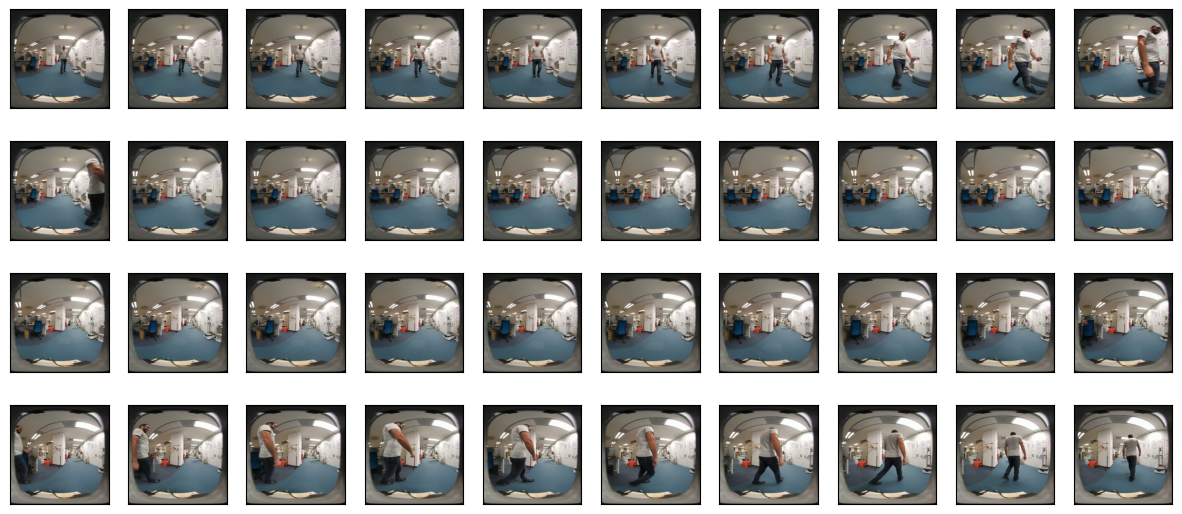

<Figure size 2000x500 with 0 Axes>

In [28]:
# memo: data20240807 1720, 210, 300, 520, 500, 3500
batch, vid_idx, path = o_valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.permute(1,0).reshape(1,args.sequence_length,2)
print(vid_idx, path)
visual_vid_mmot(batch, mot, rgb=True,mot_viz=False, grid=False)

### Save the video

In [109]:
import cv2
import numpy as np

# 假设 blended_video 是混合后的帧，形状为 (8, 64, 64, 3)

def save_video(frames, motion, output_path, fps=10):
    # 获取帧的宽度和高度（假设所有帧大小一致）
    height, width, _ = frames[0].shape
    
    # 定义视频编码器, 选择一个合适的编码器，例如 MJPG 或 MP4
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')

    # 创建 VideoWriter 对象
    out = cv2.VideoWriter(output_path, fourcc, fps, (256, 256))
    start_x, start_y = width // 2, height - 5  # 从视频中心开始

    # 将每一帧写入视频
    for i in range(args.sequence_length - frame_t):
        frame = frames[i]
        speed = motion[i, 0]  # 前后的移动速度
        angle = motion[i, 1]  # 转角（弧度）
        # 计算箭头的结束位置
        if abs(speed) < 0.1:
            end_x = int(start_x)
            end_y = int(start_y)  
        # elif abs(angle) < 0.1:
        #     end_x = int(start_x)
        #     end_y = int(start_y - 5 * np.cos(angle))  
        else:
            # print(np.sin(angle))
            end_x = int(start_x - 30 * np.sin(angle))
            end_y = int(start_y - 25 * np.cos(angle))  
        # end_x = int(start_x + speed * 1 * np.sin(angle))  
        # end_y = int(start_y + speed * 1 * np.cos(angle))  
        # print(3 * np.sin(angle))
        # print(end_y)

        # 绘制箭头
        arrow_color = (0, 1, 0)  # 绿色箭头
        cv2.arrowedLine(frame, (start_x, start_y), (end_x, end_y), arrow_color, thickness=2, tipLength=0.5)

        # 更新起始位置为当前结束位置
        # start_x, start_y = end_x, end_y

        if frame.dtype == np.float64:
            frame = (frame * 255).astype(np.uint8)
        # 如果帧是 RGB 格式，需要转换为 BGR 格式
        frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
        frame_bgr = cv2.resize(frame_bgr,(256,256))
        # 写入视频文件
        out.write(frame_bgr)
    
    # 释放 VideoWriter 对象
    out.release()
    print(f"视频已保存为 {output_path}")

########## choose one video generated by model ####################
index = 1
vid = rec_vid_list[index]
mot = rec_mot_list[index][frame_t:].cpu().numpy()
bg_frame = np.float64(batch[frame_t-1].numpy())

########## Resize the generated video to (256,256) ####################
later_frames = vid[frame_t:].numpy()
resized_frames = []
print(later_frames.shape)
for frame in later_frames:  # 逐帧处理
    resized_frame = cv2.resize(frame, (256, 256))  # 调整为 256x256
    resized_frames.append(resized_frame)

# 转换为 NumPy 数组形式，形状为 (8, 256, 256, channels)
resized_frames = np.array(resized_frames)

alpha = 0.3
blended_frames = []

for i in range(args.sequence_length - frame_t):
    # 将背景帧与当前帧进行混合
    blended_frame = cv2.addWeighted(bg_frame, alpha, resized_frames[i], 1- alpha, 0)
    blended_frames.append(blended_frame)

blended_video = np.array(blended_frames)




save_video(blended_video, mot, 'output_video.mp4', fps=2)
!echo "y" | ffmpeg -i output_video.mp4 -c:v libx264 -crf 23 -preset fast video1_t.mp4
!rm output_video.mp4

(30, 64, 64, 3)
视频已保存为 output_video.mp4
ffmpeg version 4.2.7-0ubuntu0.1 Copyright (c) 2000-2022 the FFmpeg developers
  built with gcc 9 (Ubuntu 9.4.0-1ubuntu1~20.04.1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-avresample --disable-filter=resample --enable-avisynth --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librsvg --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libssh --enable-libtheora --enable-libtwolame --

In [106]:
from IPython.display import Video,clear_output
clear_output(wait=True)
Video("video1_t.mp4")
